# Scaling: what a full-depth soft tree costs

The deck lists two cost limitations of difftree:

- **Fixed, full depth.** A depth-$D$ tree always has $2^D - 1$ splits and $2^D$ leaves, whether the data need them or not.
- **Every leaf is evaluated.** Soft routing computes a path probability for every leaf, so prediction is $O(2^D)$ per input, while a hard tree follows one path in $O(D)$.

This notebook measures both on the Friedman #1 benchmark (`sklearn.datasets.make_friedman1`: 5 informative inputs plus noise inputs) and compares against scikit-learn's `DecisionTreeRegressor`. All timings are wall-clock on the machine that ran the notebook (CPU), so read the slopes, not the absolute numbers. Fit times include JIT compilation and calibration, which is why shallow trees do not fit in near-zero time.

In [1]:
import platform, time
from pathlib import Path

import jax
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_friedman1
from sklearn.tree import DecisionTreeRegressor

from difftree import DifferentiableTreeRegressor

FIG = Path("../presentation/figures")
print(platform.processor() or platform.machine(), "| jax", jax.__version__, "| devices:", jax.devices())


def data(n, p=10, seed=0):
    X, y = make_friedman1(n_samples=n, n_features=p, noise=0.5, random_state=seed)
    return X, y


def best_time(f, repeat=3):
    f()                                   # warm-up (JIT compile)
    ts = []
    for _ in range(repeat):
        t = time.perf_counter(); f(); ts.append(time.perf_counter() - t)
    return min(ts)

arm | jax 0.10.0 | devices: [CpuDevice(id=0)]


## 1. Parameters grow as $2^D$

Each split has $p$ weights and a bias; each leaf has a mean (plus, for affine leaves, a $d_y \times p$ slope matrix) and a noise term. The count below is the number of trained values in the fitted `params_`, for $p = 10$ inputs and one output. The axis-aligned scikit-learn tree only stores the nodes it actually grows.

In [2]:
depths = [2, 4, 6, 8, 10, 12]
X, y = data(2000)
counts = {"difftree, constant leaves": [], "difftree, affine leaves": []}
for D in depths:
    for name, kw in (("difftree, constant leaves", {}), ("difftree, affine leaves", {"leaf_type": "affine"})):
        m = DifferentiableTreeRegressor(depth=D, n_epochs=1, n_calibration_steps=1, random_state=0, **kw).fit(X, y)
        # constant leaves keep an all-zero leaf_A array that is never trained; don't count it
        counts[name].append(sum(np.size(v) for k, v in m.params_.items() if kw or k != "leaf_A"))
sk_nodes = [DecisionTreeRegressor(max_depth=D, random_state=0).fit(X, y).tree_.node_count for D in depths]

for name, c in counts.items():
    print(f"{name:>28s}:", c)
print(f"{'sklearn tree (nodes)':>28s}:", sk_nodes)

   difftree, constant leaves: [44, 202, 828, 3326, 13312, 53250]
     difftree, affine leaves: [84, 362, 1468, 5886, 23552, 94210]
        sklearn tree (nodes): [7, 31, 127, 503, 1395, 2405]


## 2. Fit time against depth, samples and inputs

Each fit runs 20 epochs (batch size 256). Depth is the dominant cost: one epoch evaluates every leaf for every sample. Samples and inputs enter roughly linearly.

In [3]:
EPOCHS = 20
fit_depth, sk_fit_depth = [], []
for D in depths:
    t = time.perf_counter()
    DifferentiableTreeRegressor(depth=D, n_epochs=EPOCHS, random_state=0).fit(X, y)
    fit_depth.append(time.perf_counter() - t)
    sk_fit_depth.append(best_time(lambda: DecisionTreeRegressor(max_depth=D).fit(X, y)))
    print(f"depth {D:2d}: difftree {fit_depth[-1]:6.1f} s   sklearn {sk_fit_depth[-1] * 1e3:6.2f} ms", flush=True)

ns = [500, 2000, 8000, 32000]
fit_n = []
for n in ns:
    Xn, yn = data(n)
    t = time.perf_counter()
    DifferentiableTreeRegressor(depth=6, n_epochs=EPOCHS, random_state=0).fit(Xn, yn)
    fit_n.append(time.perf_counter() - t)
    print(f"n {n:6d}: {fit_n[-1]:6.1f} s", flush=True)

ps = [5, 20, 80, 320]
fit_p = []
for p in ps:
    Xp, yp = data(2000, p=p)
    t = time.perf_counter()
    DifferentiableTreeRegressor(depth=6, n_epochs=EPOCHS, random_state=0).fit(Xp, yp)
    fit_p.append(time.perf_counter() - t)
    print(f"p {p:4d}: {fit_p[-1]:6.1f} s", flush=True)

depth  2: difftree    3.6 s   sklearn   6.78 ms


depth  4: difftree    5.6 s   sklearn  12.51 ms


depth  6: difftree    8.6 s   sklearn  17.42 ms


depth  8: difftree    9.9 s   sklearn  14.74 ms


depth 10: difftree   16.3 s   sklearn  14.50 ms


...

n  32000:   16.9 s


p    5:    8.7 s


p   20:    8.2 s


p   80:    8.3 s


p  320:    9.2 s


## 3. Prediction time: soft routing evaluates every leaf

`predict()` (soft) computes all $2^D$ path probabilities and the mixture moments. `predict(hard=True)` routes each input down one path, like a classic tree, but still in NumPy over the full-depth arrays. Times are per 10,000 inputs, best of 3 after a warm-up call. The dashed line is a $2^D$ reference slope anchored at the deepest soft point.

In [4]:
Xq, _ = data(10_000, seed=1)
soft_t, hard_t, sk_t = [], [], []
for D in depths:
    m = DifferentiableTreeRegressor(depth=D, n_epochs=2, n_calibration_steps=1, random_state=0).fit(X, y)
    sk = DecisionTreeRegressor(max_depth=D, random_state=0).fit(X, y)
    soft_t.append(best_time(lambda: m.predict(Xq)))
    hard_t.append(best_time(lambda: m.predict(Xq, hard=True)))
    sk_t.append(best_time(lambda: sk.predict(Xq)))
    print(f"depth {D:2d}: soft {soft_t[-1] * 1e3:7.1f} ms  crisp {hard_t[-1] * 1e3:6.1f} ms  "
          f"sklearn {sk_t[-1] * 1e3:5.2f} ms", flush=True)

depth  2: soft    11.3 ms  crisp    2.6 ms  sklearn  0.34 ms


depth  4: soft    12.8 ms  crisp    3.1 ms  sklearn  0.78 ms


depth  6: soft    13.3 ms  crisp    3.8 ms  sklearn  0.92 ms


depth  8: soft    46.1 ms  crisp   11.7 ms  sklearn  0.87 ms


depth 10: soft   213.2 ms  crisp   28.9 ms  sklearn  1.03 ms


depth 12: soft   851.7 ms  crisp  117.0 ms  sklearn  1.24 ms


## 4. Does depth pay for itself?

Cost is only half the story. Below, test RMSE on Friedman #1 (4000 training points, 100 epochs) against depth, with scikit-learn's tree as reference. The noise standard deviation is 0.5, which is the best achievable RMSE.

In [5]:
Xtr, ytr = data(4000, seed=0)
Xte, yte = data(4000, seed=2)
acc_depths = [2, 4, 6, 8, 10]
rmse_dt, rmse_sk, t_acc = [], [], []
for D in acc_depths:
    t = time.perf_counter()
    m = DifferentiableTreeRegressor(depth=D, n_epochs=100, random_state=0).fit(Xtr, ytr)
    t_acc.append(time.perf_counter() - t)
    rmse_dt.append(np.sqrt(np.mean((m.predict(Xte) - yte) ** 2)))
    sk = DecisionTreeRegressor(max_depth=D, random_state=0).fit(Xtr, ytr)
    rmse_sk.append(np.sqrt(np.mean((sk.predict(Xte) - yte) ** 2)))
    print(f"depth {D:2d}: difftree RMSE {rmse_dt[-1]:.3f} ({t_acc[-1]:5.1f} s)   sklearn RMSE {rmse_sk[-1]:.3f}", flush=True)

depth  2: difftree RMSE 2.654 (  7.9 s)   sklearn RMSE 3.783


depth  4: difftree RMSE 1.813 (  9.5 s)   sklearn RMSE 2.797


depth  6: difftree RMSE 1.248 ( 11.5 s)   sklearn RMSE 2.350


depth  8: difftree RMSE 1.134 ( 21.4 s)   sklearn RMSE 2.108


depth 10: difftree RMSE 1.129 ( 60.8 s)   sklearn RMSE 2.056


## Summary figure

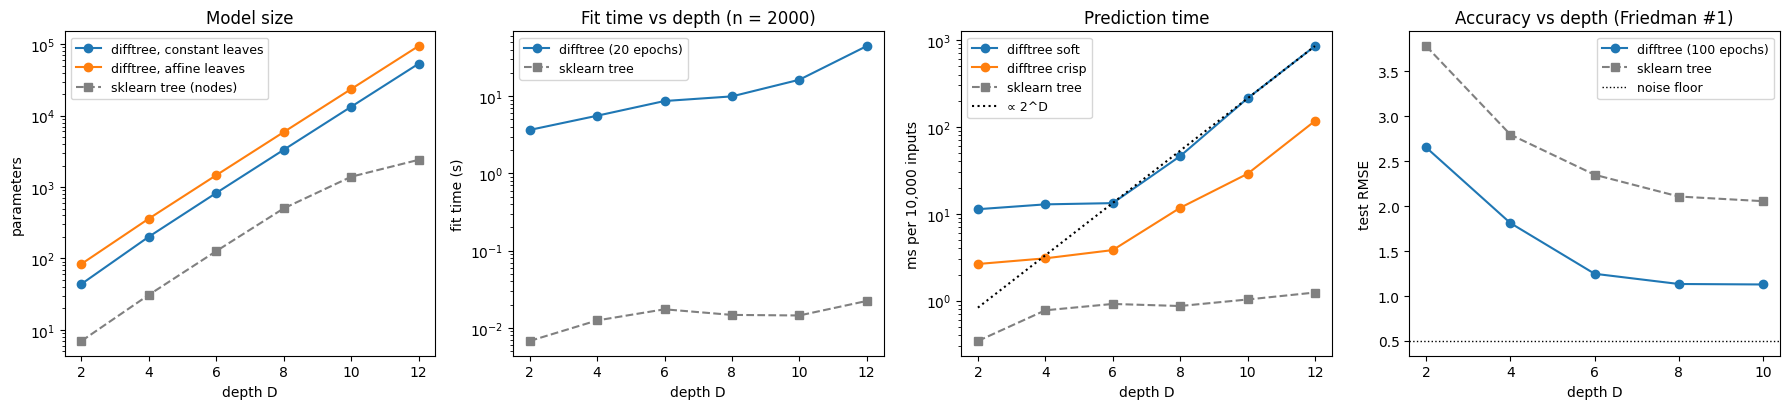

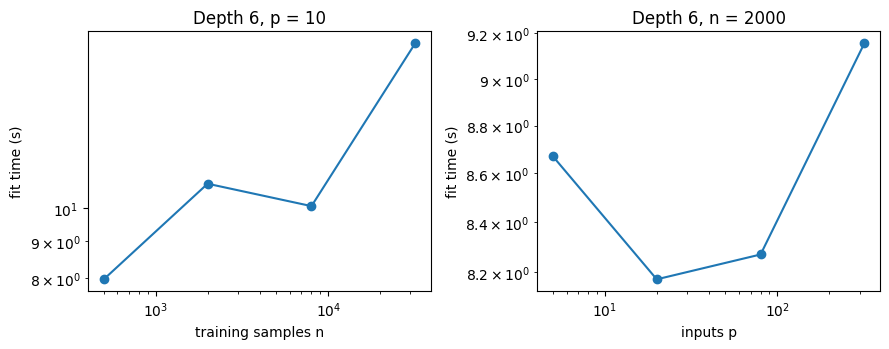

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))

ax = axes[0]
for name, c in counts.items():
    ax.semilogy(depths, c, "o-", label=name)
ax.semilogy(depths, sk_nodes, "s--", color="0.5", label="sklearn tree (nodes)")
ax.set(xlabel="depth D", ylabel="parameters", title="Model size")
ax.legend(fontsize=9)

ax = axes[1]
ax.semilogy(depths, fit_depth, "o-", label="difftree (20 epochs)")
ax.semilogy(depths, sk_fit_depth, "s--", color="0.5", label="sklearn tree")
ax.set(xlabel="depth D", ylabel="fit time (s)", title="Fit time vs depth (n = 2000)")
ax.legend(fontsize=9)

ax = axes[2]
ax.semilogy(depths, np.array(soft_t) * 1e3, "o-", label="difftree soft")
ax.semilogy(depths, np.array(hard_t) * 1e3, "o-", label="difftree crisp")
ax.semilogy(depths, np.array(sk_t) * 1e3, "s--", color="0.5", label="sklearn tree")
ref = soft_t[-1] * 1e3 * 2.0 ** (np.array(depths) - depths[-1])
ax.semilogy(depths, ref, ":", color="k", label="∝ 2^D")
ax.set(xlabel="depth D", ylabel="ms per 10,000 inputs", title="Prediction time")
ax.legend(fontsize=9)

ax = axes[3]
ax.plot(acc_depths, rmse_dt, "o-", label="difftree (100 epochs)")
ax.plot(acc_depths, rmse_sk, "s--", color="0.5", label="sklearn tree")
ax.axhline(0.5, color="k", ls=":", lw=1, label="noise floor")
ax.set(xlabel="depth D", ylabel="test RMSE", title="Accuracy vs depth (Friedman #1)")
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig(FIG / "scaling.png", dpi=150)
plt.show()

fig2, axes2 = plt.subplots(1, 2, figsize=(9, 3.6))
axes2[0].loglog(ns, fit_n, "o-")
axes2[0].set(xlabel="training samples n", ylabel="fit time (s)", title="Depth 6, p = 10")
axes2[1].loglog(ps, fit_p, "o-")
axes2[1].set(xlabel="inputs p", ylabel="fit time (s)", title="Depth 6, n = 2000")
plt.tight_layout()
plt.show()

## What this shows

Timings are wall-clock on an Apple silicon CPU and vary by 10 to 50% between runs (two runs of this notebook were compared), so read the trends, not the individual numbers.

- **Size.** Trained parameters grow by about 4x per two levels: at depth 12 with 10 inputs, about 53,000 for constant leaves and 94,000 for affine leaves, whether or not the data need that many leaves. The greedy scikit-learn tree stops growing where the data run out (about 2,400 nodes at depth 12).
- **Fit time.** A fixed cost of a few seconds (compilation, calibration) dominates shallow trees. From depth 8 to 12 the fit time grows 3.5 to 4.5x, to about 45 to 50 s for only 20 epochs, and that is what caps practical depth at 10 to 12. Samples and inputs matter much less: 64x more samples cost about 2 to 2.5x more time, and 64x more inputs cost almost nothing at depth 6, because the per-leaf work dominates.
- **Prediction.** Soft prediction is nearly flat to depth 6 and then grows by roughly 4x per two levels, the $2^D$ slope of evaluating every leaf. Crisp prediction is 4 to 8x cheaper, though it gives up the routing uncertainty. The scikit-learn tree, at $O(D)$ per input, is two to three orders of magnitude cheaper than soft prediction at depth 12.
- **Accuracy.** difftree beats the greedy tree at every depth (oblique splits and joint training), but it levels off at depth 8: going to depth 10 changes RMSE by less than 1% for about 3x the fit time. It also stays well above the noise floor of 0.5 here, so more depth is not the way to close that gap.

The practical rule: choose the smallest depth whose validation error has levelled off, and use `predict(hard=True)` when only the mean is needed at scale.